# 06 · From evidence to a recommendation

**Owner:** _[name]_ · **Reviewed by:** _[name]_ · **Covers:** spec §3 and §5, brief §8.6 (memo), decisions D1–D9, gaps G1, G2, G4, G26
**Status:** Part A (evidence for the team's decisions) drafted with AI assistance; Part B (the verdict) runs only after the team has locked its inputs.

**Part A** gives the team the evidence to choose each open decision. Not every decision is estimated the same way:

| Kind | Decisions | How a statistician justifies it |
|---|---|---|
| **Preference** (no "true value" in the data) | D1 spending, D2 crisis budget, D8 risk-share cap | Decision analysis: show the consequence of every option, find the **break-even** point where the verdict flips, check the plausible range against it |
| **Uncertain quantity** | D4 equity risk premium, AGG spread | External evidence + data for a range; break-even test of the verdict |
| **Design rule** | D3 caps, D5 shock horizon, D9 monitoring trigger | Fitness for purpose; D9 is **backtested** (designed on 2008–18, confirmed on 2019–22) |
| **Governance** | D6 owners, D7 freeze date | No statistics: the team decides |

**Rules:** explore on data ≤ 2022 only; the team chooses **one central value** (so the verdict is mechanical) **and states the plausible range** with a robustness sentence; values are locked in `doc/decisions/inputs_lock.md` **before** Part B and the final test. Choosing values until the portfolio passes is data snooping and is not allowed.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
from arch import arch_model
from matplotlib.colors import to_rgba

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
wide = lambda col: raw.pivot(index="date", columns="ticker", values=col).sort_index()[TICKERS]
adj, close, div = wide("adj_close"), wide("close"), wide("dividends").fillna(0)
R = adj.pct_change(fill_method=None).iloc[1:]

def fred(name):
    s = pd.read_parquet(RAW / f"fred_{name}.parquet").iloc[:, -1]
    s.index = pd.to_datetime(s.index)
    return s.loc[:END].dropna()

EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # spec §4; AGG = D3 (provisional)
LEVELS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
NAV = 10_000_000
rng = np.random.default_rng(20261028)

def min_var_at(x, S):
    res = optimize.minimize(lambda w: w @ S @ w, np.full(7, 1 / 7), method="SLSQP",
                            bounds=[(0.0, CAPS[t]) for t in TICKERS],
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                         {"type": "eq", "fun": lambda w: EQ @ w - x}], options={"ftol": 1e-12})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

S_now = LedoitWolf().fit(R.iloc[-756:].to_numpy()).covariance_ * 252           # optimiser window (as notebook 02)
S_long = LedoitWolf().fit(R.to_numpy()).covariance_ * 252                       # long-run risk for the volatility drag
WEIGHTS = {x: min_var_at(x, S_now) for x in LEVELS}

def path_loss(r):
    v = (1 + r).cumprod(); return float(-(v / np.maximum(v.cummax(), 1.0) - 1).min())
CRISES = {"GFC 2008": ("2007-10-09", "2009-03-09"), "COVID 2020": ("2020-02-19", "2020-03-23"), "Rate shock 2022": ("2022-01-03", "2022-10-12")}
def crisis_loss(w):
    return max(path_loss(R.loc[(R.index > a) & (R.index <= b)] @ w) for a, b in CRISES.values())
CRISIS = {x: crisis_loss(wx) for x, wx in WEIGHTS.items()}
print("worst historical crisis loss with today's weights:", {f"{x:.0%}": f"{v:.1%}" for x, v in CRISIS.items()})

worst historical crisis loss with today's weights: {'20%': '18.2%', '25%': '20.2%', '30%': '22.4%', '35%': '24.4%', '40%': '26.6%', '45%': '29.0%', '50%': '31.9%'}


## A1 · D4: the equity risk premium and the AGG spread (uncertain quantities)

Forward-looking expected returns (spec §3.1) need two inputs no one can observe exactly. Evidence:
1. **Our data:** the realised premium of SPY over T-bills and of AGG over a Treasury proxy, 2004–2022. One sample period is weak evidence (it depends on where it starts and ends), so it only frames the range.
2. **Outside evidence:** academic and practitioner estimates put the forward US equity premium roughly in a **3–6%** band. The owner must cite the specific sources used (for example long-run historical premia and implied-ERP estimates).

The verdict's sensitivity to the ERP is tested by its **break-even** value in A3.

In [3]:
rf_d = ((1 + 365 * (fred("DTB3").reindex(R.index, method="ffill") / 100) /
         (360 - 91 * fred("DTB3").reindex(R.index, method="ffill") / 100)) ** (1 / 252) - 1).shift(1).bfill()
years = len(R) / 252
spy_x = float((1 + R["SPY"]).prod() ** (1 / years) - (1 + rf_d).prod() ** (1 / years))
# Treasury proxy with AGG-like duration (about 6): yield of a 2/10-year blend, carry plus duration effect
y_mid = (fred("DGS2") + fred("DGS10")).reindex(R.index, method="ffill") / 200
tsy = y_mid.shift(1) / 252 - 6.0 * y_mid.diff()
agg_x = float((1 + R["AGG"]).prod() ** (1 / years) - (1 + tsy.fillna(0)).prod() ** (1 / years))
print(f"realised 2004-22: SPY over T-bills {spy_x:+.2%} a year; AGG over a duration-6 Treasury proxy {agg_x:+.2%} a year")
print(f"end-2022 market levels: 10-year yield {fred('DGS10').iloc[-1]:.2f}%, 2-year {fred('DGS2').iloc[-1]:.2f}%, "
      f"10-year breakeven inflation {fred('T10YIE').iloc[-1]:.2f}%, real yield {fred('DFII10').iloc[-1]:.2f}%")

realised 2004-22: SPY over T-bills +7.55% a year; AGG over a duration-6 Treasury proxy +0.90% a year
end-2022 market levels: 10-year yield 3.88%, 2-year 4.41%, 10-year breakeven inflation 2.30%, real yield 1.58%


**Evidence:**
- **ERP.** In our sample SPY beat T-bills by 7.6% a year, above the usual 3–6% band, because 2004–22 was an exceptional period for US stocks (valuations rose). It frames the top of the range; it is not a forecast.
- **AGG spread.** AGG beat a duration-6 Treasury proxy by about 0.9% a year (a crude proxy that also picks up its mortgage and corporate premia), so a 0.5% central spread is on the cautious side; the plausible range is 0.3–0.9%.
- **Market levels at end-2022:** 10-year yield 3.88%, 2-year 4.41% (an inverted curve, during a hiking cycle), breakeven inflation 2.30%.
- **Definition matters.** Our ERP is **arithmetic**, and we subtract the volatility drag σ²/2. A geometric ERP would add about 0.3 pp at 35% equity (immaterial) but about 2 pp for 100% equity.

**Agreed D4 (2026-10-28):** ERP **4.5%** (arithmetic; range 3.5–5.5%), AGG spread 0.5% (range 0.3–0.9%), stated as a **disclosed assumption**: anchored on this approved data and only cross-checked against published estimates (booklet p. 9: no undisclosed or proprietary data sources). A3 shows how much the verdict depends on it.

## A2 · D1 and D2 together: the decision map

Spending (D1) sets how much return the fund needs; the crisis budget (D2) sets how much equity it may hold. They must be chosen **together**, because one trades against the other.

For every frontier point we compute the **net forward expected return** (spec §3.1: AGG = 10-year yield + spread; equities = 10-year yield + β × ERP; gold = breakeven inflation; minus expense ratios and US withholding tax on equity dividends; minus the volatility drag σ²/2), and its **worst historical crisis loss** with today's weights. The required return is (1 + spending)(1 + breakeven inflation) − 1.

Verdict for each (spending, budget) pair, by the spec §5 rule: **ACCEPT** if some point meets the required return within the budget (recommend the lowest-risk one); **ADJUST** if one does with the budget loosened by at most 5 pp; otherwise **REJECT**.

**Cost assumptions** (to verify on the issuers' pages; used as costs, not as data): expense ratios SPY 0.09%, EFA 0.33%, EEM 0.70%, AGG 0.03%, GLD 0.40%, XLE 0.09%, XLK 0.09%; trading about 0.01% a year; 15% withholding on equity dividends; AGG assumed exempt (sensitivity in A3).

breakeven inflation 2.30%; required return at the agreed 3% spending + 0.5% growth: 5.90%


,net forward return,worst crisis loss
20%,4.32%,18.17%
25%,4.54%,20.24%
30%,4.75%,22.36%
35%,4.91%,24.41%
40%,4.99%,26.59%
45%,5.04%,29.00%
50%,5.07%,31.88%


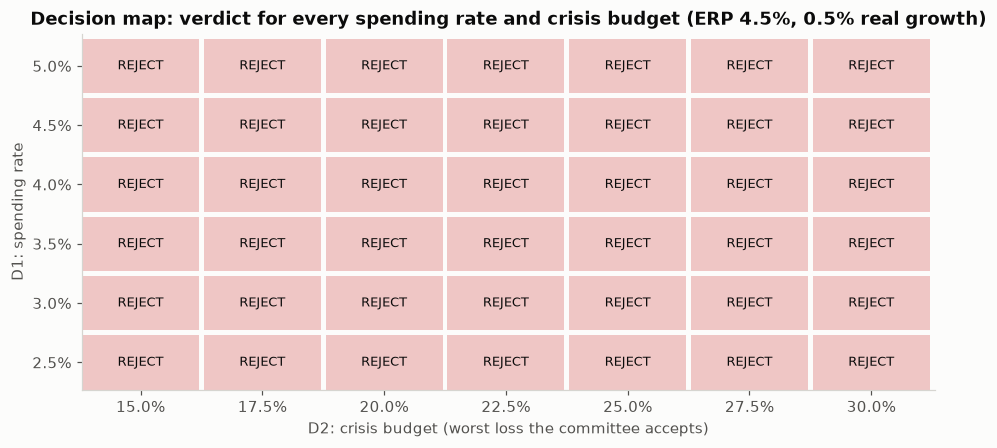

In [4]:
ERP_C, SPREAD_C, GROWTH = 0.045, 0.005, 0.005                        # agreed D4 (ERP, AGG spread) and the real-growth margin (D1)
EXPENSE = pd.Series({"SPY": .000945, "EFA": .0033, "EEM": .0070, "AGG": .0003, "GLD": .0040, "XLE": .0009, "XLK": .0009})
y10, pi = fred("DGS10").iloc[-1] / 100, fred("T10YIE").iloc[-1] / 100
est = R.iloc[-756:]
beta = (est.cov()["SPY"] / est["SPY"].var()).reindex(TICKERS)
div_yield = (div.loc[R.index[-1] - pd.Timedelta(days=365):].sum() / close.iloc[-1]).reindex(TICKERS)
WHT = pd.Series({t: 0.15 if t in EQUITY else 0.0 for t in TICKERS})

def expected_return(w, erp=ERP_C, spread=SPREAD_C, agg_wht=0.0, dy=0.0):
    """Net geometric forward return; dy shifts the 10-year yield with inflation unchanged (a real-yield scenario)."""
    y = y10 + dy
    mu = pd.Series({t: (y + spread if t == "AGG" else pi if t == "GLD" else y + beta[t] * erp) for t in TICKERS})
    wht = WHT.copy(); wht["AGG"] = agg_wht
    net = mu - EXPENSE.reindex(TICKERS) - div_yield * wht - 0.0001
    return float(w @ net.to_numpy() - 0.5 * w @ S_long @ w)      # geometric (compound) return

def required(s):
    return (1 + s) * (1 + GROWTH) * (1 + pi) - 1          # spending + real growth + inflation (objective: CPI + s + 0.5%)

def verdict(s, dmax, erp=ERP_C, spread=SPREAD_C, agg_wht=0.0, dy=0.0):
    er = lambda x: expected_return(WEIGHTS[x], erp, spread, agg_wht, dy)
    ok = [x for x in LEVELS if CRISIS[x] <= dmax + 1e-9 and er(x) >= required(s)]
    if ok:
        return "ACCEPT", min(ok)
    near = [x for x in LEVELS if CRISIS[x] <= dmax + 0.05 + 1e-9 and er(x) >= required(s)]
    return ("ADJUST", min(near)) if near else ("REJECT", None)

fwd = pd.DataFrame({"net forward return": {f"{x:.0%}": expected_return(WEIGHTS[x]) for x in LEVELS},
                    "worst crisis loss": {f"{x:.0%}": CRISIS[x] for x in LEVELS}})
print(f"breakeven inflation {pi:.2%}; required return at the agreed 3% spending + 0.5% growth: {required(0.03):.2%}")
display(fwd.style.format("{:.2%}"))

SPEND = [0.025, 0.030, 0.035, 0.040, 0.045, 0.050]
DMAX = [0.150, 0.175, 0.200, 0.225, 0.250, 0.275, 0.300]
grid = {(s, d): verdict(s, d) for s in SPEND for d in DMAX}
COLOR = {"ACCEPT": "#0ca30c", "ADJUST": "#fab219", "REJECT": "#d03b3b"}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, s in enumerate(SPEND):
    for j, d in enumerate(DMAX):
        v, x = grid[(s, d)]
        ax.add_patch(plt.Rectangle((j, i), 0.96, 0.92, color=to_rgba(COLOR[v], 0.28), linewidth=0))
        ax.text(j + 0.48, i + 0.46, v + ("" if x is None else f"\n{x:.0%} equity"), ha="center", va="center", fontsize=8.5, color=INK)
ax.set(xlim=(0, len(DMAX)), ylim=(0, len(SPEND)), xlabel="D2: crisis budget (worst loss the committee accepts)",
       ylabel="D1: spending rate", title="Decision map: verdict for every spending rate and crisis budget (ERP 4.5%, 0.5% real growth)")
ax.set_xticks(np.arange(len(DMAX)) + 0.48, [f"{d:.1%}" for d in DMAX]); ax.set_yticks(np.arange(len(SPEND)) + 0.46, [f"{s:.1%}" for s in SPEND])
ax.grid(False)
plt.show()

**Evidence:** at end-2022 market levels the agreed objective (3% spending + 0.5% real growth + inflation = **5.9%** required) is **not** met within any plausible crisis budget: the net forward return runs from 4.3% (20% equity) to 5.1% (50% equity). Budgets of 15% and 17.5% have no feasible point at all (the caps force at least 20% equity, which lost 18.2% in the GFC). On end-2022 levels the binding problem is the market's low real yield, not the risk budget.

### A2b · The more useful question: what spending can each crisis budget sustainably fund?

Turn the question around: for each crisis budget and ERP, take the best feasible point (the highest net forward return whose worst crisis loss fits the budget) and compute the spending rate it can fund while still growing 0.5% a year in real terms: (1 + return) / ((1 + inflation)(1 + 0.5%)) − 1. Two reference portfolios **outside the IPS** (60/40 SPY/AGG and 100% SPY) show what it would take.

,ERP 3.5%,ERP 4.5%,ERP 5.5%,equity share used (ERP 4.5%)
15.0%,none feasible,none feasible,none feasible,nan%
17.5%,none feasible,none feasible,none feasible,nan%
20.0%,1.29%,1.47%,1.64%,20%
22.5%,1.63%,1.88%,2.14%,30%
25.0%,1.75%,2.05%,2.34%,35%
27.5%,1.78%,2.12%,2.46%,40%
30.0%,1.78%,2.16%,2.54%,45%


,"sustainable spending, ERP 3.5%","sustainable spending, ERP 4.5%","sustainable spending, ERP 5.5%",worst crisis loss
60/40 SPY/AGG,2.37%,2.95%,3.54%,34.70%
100% SPY,2.24%,3.21%,4.18%,55.19%


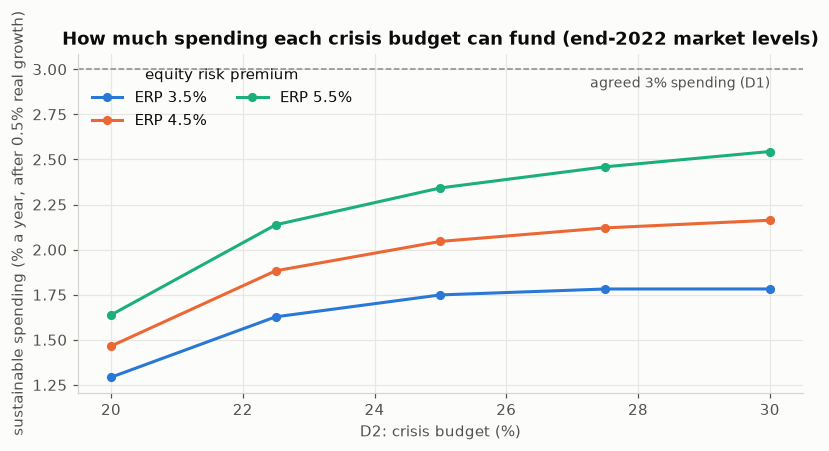

In [5]:
def best_feasible(dmax, erp):
    feas = [x for x in LEVELS if CRISIS[x] <= dmax + 1e-9]
    if not feas:
        return None, np.nan
    x = max(feas, key=lambda v: expected_return(WEIGHTS[v], erp))
    return x, (1 + expected_return(WEIGHTS[x], erp)) / ((1 + pi) * (1 + GROWTH)) - 1
ERPS = [0.035, 0.045, 0.055]
sust = pd.DataFrame({f"ERP {e:.1%}": {f"{d:.1%}": best_feasible(d, e)[1] for d in DMAX} for e in ERPS})
used = pd.Series({f"{d:.1%}": best_feasible(d, ERP_C)[0] for d in DMAX}, name="equity share used (ERP 4.5%)")
display(pd.concat([sust, used.map(lambda v: "none feasible" if v is None else f"{v:.0%}")], axis=1)
        .style.format({c: "{:.2%}" for c in sust.columns}, na_rep="none feasible"))
ref_w = {"60/40 SPY/AGG": np.array([.6 if t == "SPY" else .4 if t == "AGG" else 0 for t in TICKERS]),
         "100% SPY": np.array([1.0 if t == "SPY" else 0 for t in TICKERS])}
ref = pd.DataFrame({k: {**{f"sustainable spending, ERP {e:.1%}": (1 + expected_return(wv, e)) / ((1 + pi) * (1 + GROWTH)) - 1 for e in ERPS},
                        "worst crisis loss": crisis_loss(wv)} for k, wv in ref_w.items()}).T
display(ref.style.format("{:.2%}").set_caption("Reference portfolios outside the IPS"))
fig, ax = plt.subplots(figsize=(8.5, 4))
for e, colr in zip(ERPS, [BLUE, ORANGE, AQUA]):
    ax.plot([d * 100 for d in DMAX], sust[f"ERP {e:.1%}"] * 100, color=colr, marker="o", markersize=5, label=f"ERP {e:.1%}")
ax.axhline(3.0, color=GREY, linestyle="--", linewidth=1)
ax.text(DMAX[-1] * 100, 2.96, "agreed 3% spending (D1)", color=INK2, fontsize=9, ha="right", va="top")
ax.set(xlabel="D2: crisis budget (%)", ylabel="sustainable spending (% a year, after 0.5% real growth)",
       title="How much spending each crisis budget can fund (end-2022 market levels)")
ax.legend(loc="upper left", title="equity risk premium", ncol=2)
plt.show()

**Evidence:**
- **At end-2022 levels, a 25% crisis budget funds about 2.0% spending** while still growing 0.5% a year in real terms (1.75–2.34% for ERP 3.5–5.5%).
- The curve flattens above 25%: more crisis budget buys little extra capacity, because equity is capped at 50% and extra equity adds little net return after costs and drag.
- Even outside the IPS, 60/40 funds about 2.95% (with a 35% crisis loss) and 100% SPY 3.2% (with a 55% loss).

The committee's choice is therefore driven far more by the **market's real yield** than by the risk budget (A2c).

## A3 · How robust is the verdict? Break-even values

For each spending rate, the **break-even ERP** is the lowest equity risk premium at which an acceptable point exists within a 25% crisis budget. If the plausible ERP range (3–6%) lies above it, the verdict is robust to D4. We repeat it with a lower AGG spread and with AGG taxed.

In [6]:
def breakeven_erp(s, dmax=0.25, spread=SPREAD_C, agg_wht=0.0):
    for erp in np.arange(0.0, 0.1001, 0.0005):
        if verdict(s, dmax, erp, spread, agg_wht)[0] == "ACCEPT":
            return erp
    return np.nan
rows = []
for s in SPEND:
    rows.append({"spending": f"{s:.1%}", "required return": required(s),
                 "break-even ERP (central)": breakeven_erp(s),
                 "with AGG spread 0.3%": breakeven_erp(s, spread=0.003),
                 "with AGG taxed 15%": breakeven_erp(s, agg_wht=0.15),
                 "verdict at ERP 3.5% / 4.5% / 5.5%": " / ".join(f"{verdict(s, 0.25, e)[0]}" for e in (0.035, 0.045, 0.055))})
pd.DataFrame(rows).set_index("spending").style.format({c: "{:.2%}" for c in ["required return", "break-even ERP (central)",
                                                                             "with AGG spread 0.3%", "with AGG taxed 15%"]}, na_rep="none ≤ 10%")

,required return,break-even ERP (central),with AGG spread 0.3%,with AGG taxed 15%,verdict at ERP 3.5% / 4.5% / 5.5%
spending,,,,,
2.5%,5.38%,6.05%,6.50%,6.80%,REJECT / REJECT / ADJUST
3.0%,5.90%,7.75%,8.15%,8.50%,REJECT / REJECT / REJECT
3.5%,6.41%,9.45%,9.85%,none ≤ 10%,REJECT / REJECT / REJECT
4.0%,6.92%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT
4.5%,7.44%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT
5.0%,7.95%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT


**Evidence:** at end-2022 levels, 3% spending would need an ERP of **7.75%**, far above any plausible value; 2.5% spending needs about 6%. So at those levels the verdict "not achievable" is robust to D4, the AGG spread and the tax treatment. What moves it is the yield level (A2c).

## A2c · What if real yields are higher at the decision date?

The dry run uses end-2022 market levels. The decision date is later, and the test lock forbids reading 2023+ data before the freeze, so instead of looking we **shift the 10-year yield** by +0.5, +1.0 and +1.5 pp with inflation unchanged (a real-yield scenario). This shows how much the conclusion depends on the market level at the decision date; the real figure is computed after the freeze.

In [7]:
rows = []
for dy in [0.0, 0.005, 0.010, 0.015]:
    for e in [0.035, 0.045, 0.055]:
        feas = [x for x in LEVELS if CRISIS[x] <= 0.25 + 1e-9]
        best = max(feas, key=lambda v: expected_return(WEIGHTS[v], e, dy=dy))
        cap = (1 + expected_return(WEIGHTS[best], e, dy=dy)) / ((1 + pi) * (1 + GROWTH)) - 1
        v, x = verdict(0.03, 0.25, e, dy=dy)
        rows.append({"real yield shift": f"+{dy:.1%}", "ERP": f"{e:.1%}", "sustainable spending (25% budget)": cap,
                     "verdict for 3% spending": v + ("" if x is None else f" at {x:.0%} equity")})
ry = pd.DataFrame(rows)
display(ry.pivot(index="real yield shift", columns="ERP", values="sustainable spending (25% budget)").style.format("{:.2%}"))
ry.pivot(index="real yield shift", columns="ERP", values="verdict for 3% spending")

ERP,3.5%,4.5%,5.5%
real yield shift,,,
+0.0%,1.75%,2.05%,2.34%
+0.5%,2.23%,2.53%,2.82%
+1.0%,2.71%,3.01%,3.31%
+1.5%,3.20%,3.49%,3.79%


ERP,3.5%,4.5%,5.5%
real yield shift,,,
+0.0%,REJECT,REJECT,REJECT
+0.5%,REJECT,REJECT,ADJUST at 45% equity
+1.0%,REJECT,ACCEPT at 35% equity,ACCEPT at 30% equity
+1.5%,ACCEPT at 30% equity,ACCEPT at 30% equity,ACCEPT at 25% equity


**Evidence:**
- **The verdict depends on the real yield at the decision date.** At end-2022 levels the agreed 3% spending fails for every plausible ERP.
- With the 10-year real yield **1 pp higher** (inflation unchanged), the 25% budget funds about **3.0% spending with 0.5% growth at ERP 4.5%**, and the verdict becomes **ACCEPT at 35% equity**.
- At +1.5 pp it is ACCEPT for every ERP in the range; at +0.5 pp it is still REJECT (or ADJUST at the top ERP).

**What it means:** D1 = 3% sits right at the break-even of a +1 pp real-yield move. If the decision-date real yield is at least about 1 pp above end-2022 (2.6% or more on the 10-year TIPS yield), the mandate is ACCEPT with the agreed objective; if not, D10's fallback applies (ADJUST THE RISK LIMIT, with the dollar cost). This is computed after the freeze from the locked inputs; nothing here uses 2023+ data.

## A4 · D1 in the long run: will the fund keep its purchasing power? (context, not a verdict criterion)

Ten years of monthly returns are resampled from 2005–2022 together with US inflation (stationary bootstrap, mean block 12 months, so crises and recoveries stay together), with each portfolio's mean re-centred to its forward estimate. Spending is the rate × the average value of the previous 36 months, paid monthly. We report the probability that the **real** value (after inflation and spending) ends below 80% of today's.

In [8]:
cpi = fred("CPIAUCSL")
monthly = (1 + R.loc["2005-01-01":]).resample("ME").prod() - 1
infl_m = cpi.pct_change().reindex(monthly.index, method="ffill").to_numpy()

def simulate(x, s, block=12, paths=5000, months=120):
    r = (monthly @ WEIGHTS[x]).to_numpy()
    target = (1 + expected_return(WEIGHTS[x])) ** (1 / 12) - 1
    r = r - r.mean() + target                                         # re-centre to the forward estimate
    f = infl_m - infl_m.mean() + ((1 + pi) ** (1 / 12) - 1)            # inflation re-centred to the breakeven
    n = len(r)
    idx = rng.integers(0, n, paths)
    value, price, hist = np.ones(paths), np.ones(paths), [np.ones(paths)] * 36
    for _ in range(months):
        value = value * (1 + r[idx]); price = price * (1 + f[idx])
        hist = hist[1:] + [value]
        value = value - s / 12 * np.mean(hist, axis=0)
        jump = rng.random(paths) < 1 / block
        idx = np.where(jump, rng.integers(0, n, paths), (idx + 1) % n)
    real = value / price
    return float(np.mean(real < 0.8)), float(np.median(real)), float(np.sqrt(np.mean(real < 0.8) * (1 - np.mean(real < 0.8)) / paths))

rows = []
for x in [0.20, 0.35, 0.50]:
    for s in [0.030, 0.035, 0.040]:
        p, med, se = simulate(x, s)
        rows.append({"equity": f"{x:.0%}", "spending": f"{s:.1%}", "P(real value < 80%)": p, "Monte Carlo s.e.": se, "median real value": med})
sim = pd.DataFrame(rows)
blocks = {f"block {b} months": simulate(0.35, 0.03, block=b)[0] for b in (1, 12, 36)}
display(sim.pivot(index="equity", columns="spending", values="P(real value < 80%)").style.format("{:.1%}"))
display(sim.pivot(index="equity", columns="spending", values="median real value").style.format("{:.2f}"))
print("block-length sensitivity, 35% equity at 3% spending:", {k: f"{v:.1%}" for k, v in blocks.items()})

spending,3.0%,3.5%,4.0%
equity,,,
20%,31.1%,38.4%,47.3%
35%,25.8%,30.7%,40.0%
50%,28.6%,34.6%,41.8%


spending,3.0%,3.5%,4.0%
equity,,,
20%,0.90,0.86,0.81
35%,0.95,0.91,0.85
50%,0.95,0.90,0.85


block-length sensitivity, 35% equity at 3% spending: {'block 1 months': '25.6%', 'block 12 months': '25.2%', 'block 36 months': '20.2%'}


**Evidence:** even at end-2022 levels (the cautious case), 3% spending at 35% equity gives about a **26% chance that real value ends below 80% within 10 years**, with a median real value of 0.95. That compares with about 40% at 4% spending (median 0.85). The block-length sensitivity is 20–26%, Monte Carlo standard error about 0.6 pp. Cutting spending from 4% to 3% roughly halves the risk of a large loss of purchasing power, and that is in the low-yield case.
**The committee sentence:** “At 3% spending the fund keeps most of its purchasing power in most scenarios; at 4% it has close to an even chance of losing a fifth of it within ten years.”

## A5 · D5: over what horizon should the hypothetical shock be applied?

The hypothetical stagflation scenario needs a horizon: a one-day shock, a month or a quarter. The evidence is how past crises actually unfolded for today's 35% portfolio: how much of each crisis loss came within the worst day, month and quarter.

In [9]:
w35 = WEIGHTS[0.35]
rows = []
for name, (a, b) in CRISES.items():
    r = R.loc[(R.index > a) & (R.index <= b)] @ w35
    lv = np.log1p(r)
    worst = {h: float(-np.expm1(lv.rolling(h).sum().min())) if len(lv) >= h else np.nan for h in (1, 21, 63)}
    total = path_loss(r)
    rows.append({"crisis": name, "trading days": len(r), "total loss": total, "worst day": worst[1],
                 "worst month (21d)": worst[21], "worst quarter (63d)": worst[63],
                 "share of total in worst quarter": worst[63] / total if np.isfinite(worst[63]) else np.nan})
pd.DataFrame(rows).set_index("crisis").style.format({c: "{:.1%}" for c in ["total loss", "worst day", "worst month (21d)",
                                                                           "worst quarter (63d)", "share of total in worst quarter"]}, na_rep="n/a")

,trading days,total loss,worst day,worst month (21d),worst quarter (63d),share of total in worst quarter
crisis,,,,,,
GFC 2008,355,24.4%,5.3%,18.1%,19.9%,81.4%
COVID 2020,23,15.5%,6.3%,14.0%,n/a,n/a
Rate shock 2022,195,18.8%,2.3%,8.2%,9.9%,52.4%


**Evidence:** crises unfold at very different speeds. The GFC delivered 81% of its loss within its worst quarter; COVID lost 15.5% in 23 trading days; the 2022 rate shock was a slow grind, with only 52% of its loss within any single quarter over 9 months. A one-day shock would understate a 2022-type stagflation, and a one-quarter shock captures only half of it.
**Proposed D5:** apply the hypothetical stagflation shock as a **cumulative peak-to-trough episode** of about three quarters, modelled on 2022. That makes it directly comparable with D_max, which is also peak-to-trough, and the worst quarter is shown separately as the speed.

## A6 · D8: how much of the tail risk may one ETF carry?

Euler 99% ES shares (full 2004–2022 history, today's weights) for every frontier point. A cap is useful only if it is reachable and changes something.

In [10]:
rows = {}
for x, wx in WEIGHTS.items():
    l = -(R @ wx); tail = l >= l.quantile(0.99)
    share = pd.Series(wx * (-R.loc[tail].mean().to_numpy()), index=TICKERS) / l[tail].mean()
    rows[f"{x:.0%}"] = share
shares = pd.DataFrame(rows).T
shares["largest share"] = shares[TICKERS].max(axis=1)
shares["held by"] = shares[TICKERS].idxmax(axis=1)
for cap in (0.35, 0.40, 0.50):
    shares[f"meets {cap:.0%} cap"] = np.where(shares["largest share"] <= cap, "yes", "no")
shares.style.format({**{t: "{:.0%}" for t in TICKERS}, "largest share": "{:.0%}"})

,SPY,EFA,EEM,AGG,GLD,XLE,XLK,largest share,held by,meets 35% cap,meets 40% cap,meets 50% cap
20%,17%,26%,15%,27%,15%,0%,0%,27%,AGG,yes,yes,yes
25%,18%,36%,18%,21%,6%,0%,0%,36%,EFA,no,yes,yes
30%,18%,43%,20%,18%,1%,0%,0%,43%,EFA,no,no,yes
35%,18%,47%,22%,14%,0%,0%,0%,47%,EFA,no,no,yes
40%,18%,50%,22%,10%,0%,0%,0%,50%,EFA,no,no,no
45%,18%,53%,22%,7%,-0%,0%,0%,53%,EFA,no,no,no
50%,18%,54%,22%,5%,0%,0%,0%,54%,EFA,no,no,no


**Evidence:** with minimum-variance weights, EFA's share of the tail risk passes 40% from 30% equity and 50% from 40% equity. A **40% cap** binds exactly in the 30–35% range where the recommendation is likely to sit, so it forces a real resizing (towards SPY). A 35% cap would already bind at 25% equity; a 50% cap would barely ever bind.
**Proposed D8:** 40%. The resizing itself happens in Part B.

## A7 · D9: does a monitoring trigger actually protect the fund? (backtest)

Proposed rule: when the 1-day 99% ES **forecast** stays above the ES limit for N trading days in a row, move from the 35% point to the 20% point; move back when it stays below for N days. The forecast comes from a GJR-GARCH-t fitted on **2004–2018 only** (notebook 03 §5 found it passes the residual checks), then run forward without refitting, so 2019–2022 is genuinely out of sample. N is **designed on 2008–2018** and **confirmed on 2019–2022**. Switching costs 5 bp per side.

In [11]:
w20 = WEIGHTS[0.20]
p35, p20 = R @ w35, R @ w20
dev_end = "2018-12-31"
am = arch_model(p35 * 100, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
fit_dev = am.fit(last_obs=dev_end, disp="off")
sig = am.fix(fit_dev.params).conditional_volatility / 100            # sigma_t uses information up to t-1
nu, mu_ = fit_dev.params["nu"], fit_dev.params["mu"] / 100
q = st.t.ppf(0.99, nu)
es_std = st.t.pdf(q, nu) / 0.01 * (nu + q**2) / (nu - 1) * np.sqrt((nu - 2) / nu)
es_fc = -mu_ + sig * es_std
dev_l = -(R.loc[:dev_end] @ w35)
LIMIT = float(np.interp(0.25, [CRISIS[x] for x in LEVELS], [(-(R.loc[:dev_end] @ WEIGHTS[x])).pipe(lambda l: l[l >= l.quantile(0.99)].mean()) for x in LEVELS]))
print(f"ES limit used (through-the-cycle, D_max 25%): {LIMIT:.2%}; days the forecast exceeds it 2008-22: {(es_fc.loc['2008':] > LIMIT).mean():.1%}")

turn = float(np.abs(w35 - w20).sum())
def run_trigger(n, start, end):
    over = (es_fc > LIMIT).astype(int)
    state, on_run, off_run, out, switches, spells = 1, 0, 0, [], 0, []
    dates = R.loc[start:end].index
    for t in dates:
        o = over.loc[t]
        on_run = on_run + 1 if o else 0; off_run = off_run + 1 if not o else 0
        ret = p35.loc[t] if state == 1 else p20.loc[t]
        if state == 1 and on_run >= n:
            state, switches = 0, switches + 1; ret -= 5e-4 * turn; spells.append([t, None])
        elif state == 0 and off_run >= n:
            state, switches = 1, switches + 1; ret -= 5e-4 * turn; spells[-1][1] = t
        out.append(ret)
    trig = pd.Series(out, index=dates); static = p35.loc[dates]
    false = sum(1 for a, b in spells if path_loss(static.loc[a:b if b is not None else dates[-1]]) < 0.03)
    yrs = len(dates) / 252
    return {"switches / year": switches / yrs, "risk-off spells": len(spells), "false alarms (< 3% loss avoided)": false,
            "max drawdown, static": -path_loss(static), "max drawdown, trigger": -path_loss(trig),
            "return / year, static": float((1 + static).prod() ** (1 / yrs) - 1), "return / year, trigger": float((1 + trig).prod() ** (1 / yrs) - 1)}, trig

design = pd.DataFrame({n: run_trigger(n, "2008-01-01", dev_end)[0] for n in (1, 5, 10, 20)}).T
confirm = pd.DataFrame({n: run_trigger(n, "2019-01-01", END)[0] for n in (1, 5, 10, 20)}).T
fmt = {c: "{:.1%}" for c in design.columns if "drawdown" in c or "return" in c}
display(design.rename_axis("N days").style.format({**fmt, "switches / year": "{:.1f}"}).set_caption("Design period 2008–2018"))
display(confirm.rename_axis("N days").style.format({**fmt, "switches / year": "{:.1f}"}).set_caption("Confirmation period 2019–2022 (out of sample)"))

ES limit used (through-the-cycle, D_max 25%): 2.22%; days the forecast exceeds it 2008-22: 8.7%


,switches / year,risk-off spells,false alarms (< 3% loss avoided),"max drawdown, static","max drawdown, trigger","return / year, static","return / year, trigger"
N days,,,,,,,
1,2.9,16.000000,14.000000,-24.4%,-20.0%,3.8%,4.0%
5,0.7,4.000000,2.000000,-24.4%,-21.2%,3.8%,4.2%
10,0.4,2.000000,0.000000,-24.4%,-22.6%,3.8%,3.7%
20,0.4,2.000000,0.000000,-24.4%,-24.4%,3.8%,3.8%


,switches / year,risk-off spells,false alarms (< 3% loss avoided),"max drawdown, static","max drawdown, trigger","return / year, static","return / year, trigger"
N days,,,,,,,
1,3.5,7.000000,5.000000,-20.3%,-21.6%,2.8%,2.7%
5,2.0,4.000000,2.000000,-20.3%,-21.0%,2.8%,2.3%
10,1.5,3.000000,2.000000,-20.3%,-20.9%,2.8%,2.0%
20,1.0,2.000000,2.000000,-20.3%,-20.8%,2.8%,2.0%


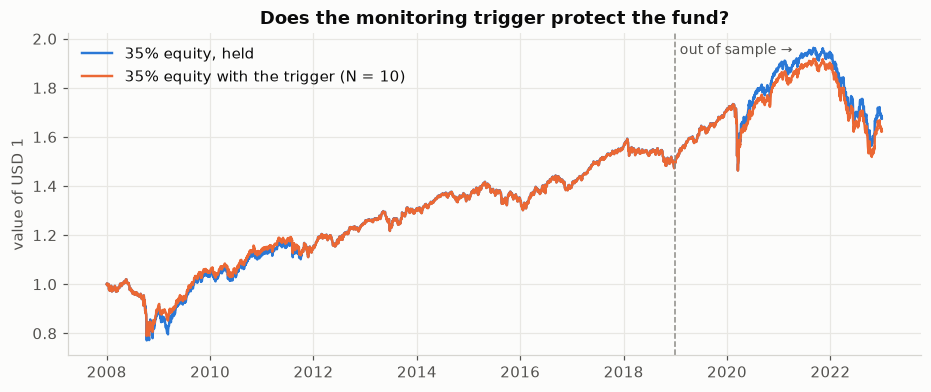

In [12]:
N_PICK = 10                                                          # provisional; the owner confirms from the design table
_, trig = run_trigger(N_PICK, "2008-01-01", END)
static = p35.loc[trig.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(static.index, (1 + static).cumprod(), color=BLUE, linewidth=1.6, label="35% equity, held")
ax.plot(trig.index, (1 + trig).cumprod(), color=ORANGE, linewidth=1.6, label=f"35% equity with the trigger (N = {N_PICK})")
ax.axvline(pd.Timestamp("2019-01-01"), color=GREY, linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2019-02-01"), ax.get_ylim()[1] * 0.98, "out of sample →", color=INK2, fontsize=9, va="top")
ax.set(ylabel="value of USD 1", title="Does the monitoring trigger protect the fund?")
ax.legend(loc="upper left")
plt.show()

**Evidence:**
- **In the design period the rule looked useful.** With N = 5 days the worst loss fell from 24.4% to 21.2%, return rose 0.4 pp a year, and there were 2 false alarms out of 4 spells. With N = 10 there were no false alarms but little protection.
- **Out of sample (2019–22) every version made things worse:** a deeper worst loss (20.8–21.6% vs 20.3%) and lower return (2.0–2.7% vs 2.8%). The COVID crash was over before the rule fired, and the fund then missed the rebound; the 2022 grind did not push the forecast high enough early enough.
- This is what over-fitting looks like: a rule tuned on one period that fails on the next.

**Proposed D9:** do **not** automate de-risking. Use the ES forecast as an **alert**: above the limit for 5 days in a row, the committee is convened to review. That keeps the governance value without trading on a signal that failed validation.

## A8 · D3, D6, D7 and the decision table for the team meeting

- **D3 (AGG cap):** notebook 02 §2 showed that moving the AGG cap between 60% and 70% changes the mix, not the risk (volatility 9.8% in every case). Decide it on concentration grounds.
- **D6 (owners) and D7 (freeze date):** governance; no statistics.

### Decisions agreed by the team (2026-10-28)

The full records, each with its booklet clause, evidence and range, are in `doc/decisions/inputs_lock.md`. Part B uses exactly these values.

| # | Decision | Agreed | Evidence here |
|---|---|---|---|
| D1 | Spending rate, return objective | **3.0%** (2.5–3.5%); objective **CPI + 3.5%** (0.5% real growth) | A2, A2b, A2c, A4 |
| D2 | Crisis budget | **25%** (20% as sensitivity) | A2b; notebook 03 §4 |
| D3 | Caps | **AGG ≤ 65%** and the spec §4 caps | notebook 02 §2 |
| D4 | ERP, AGG spread | **4.5%**, **0.5%** (disclosed assumptions) | A1, A3 |
| D5 | Shock horizon | **peak-to-trough episode of about three quarters** | A5 |
| D6 | Notebook owners | **open** | — |
| D7 | Freeze date | **open** | — |
| D8 | ES-share cap | **40%** | A6 |
| D9 | Monitoring | **alert only** (5 days → convene the committee) | A7 |
| D10 | Verdict framing | **ACCEPT with CPI + 3.5% if met, otherwise ADJUST THE RISK LIMIT** | A2–A4 |

---
# Part B · The verdict (run only after `doc/decisions/inputs_lock.md` is signed)

Each step uses the locked inputs only. Questions from the original skeleton:
1. Required return with the locked spending rate and breakeven inflation (G1).
2. Forward-looking expected returns with the locked ERP and AGG spread; the break-even ERP.
3. Limits calibrated from the locked crisis budget (G4).
4. Score the frontier; recommended point = the lowest-risk point meeting the required return and every limit; two alternatives with dollar trade-offs (G2). Apply the ES-share cap (D8) as a sizing step.
5. Ten-year spending simulation as context.
6. Verdict (spec §5); the IPS change log with the recommendation under every version (G26).
7. Base currency: one LKR-terms sensitivity line and a Sri Lanka CPI paragraph (G25).

In [13]:
# Part B: owner code here, after the input lock